# Surface BRDF

What is the relationship between rte resolution and surface reflectance at low wind speeds (<4 m/s)

In [1]:
import pathlib
from pathlib import Path
import sys
import xarray as xr
import numpy as np
import at3d
from collections import OrderedDict
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path().resolve().parent.parent
sys.path.append(str(PROJECT_ROOT))

from src.utils.util import load_sensor_dict, save_sensor_dict
from src.main.run_at3d import load_config

In [2]:
outdir = PROJECT_ROOT / 'notebooks' / 'surface_parameterization_testing' / 'output1D'
config_dir = PROJECT_ROOT / 'notebooks' / 'surface_parameterization_testing' / 'configs_expr02_fast'

In [3]:
# for config_file in config_dir.glob('*.yml'):
#     config = load_config(config_file)
    
#     # Load rte grid and observations
#     # rte_grid = xr.load_dataset(config['rte_grid_file'])
#     obs = load_sensor_dict(config['obs_file'])

#     # Make forward sensors
#     forward_sensors = obs.make_forward_sensors()
#     wavelength = forward_sensors.get_unique_solvers()[0]

#     # Define surface reflectance model based on surface wind speed
#     m_water = 1.33197 - 1j*2.41e-8
#     surface = at3d.surface.wave_fresnel(np.real(m_water), np.imag(m_water), config['surface_wind_speed'])

#     # Load SHODM numerical parameters
#     numerical_parameters = at3d.configuration.get_config(config['config_file_name'])

#     # Set solar source
#     source = at3d.source.solar(
#         wavelength,
#         -1*obs['MISR']['sensor_list'][0].mu0,
#         obs['MISR']['sensor_list'][0].SAA,
#         solarflux=1.0,
#         skyrad=0.0
#     )

#     # Load background atmosphere
#     background_properties = xr.load_dataset(config['background_scatterers_file'])
#     medium = {
#         'background': background_properties.isel(x=slice(0,1), y=slice(0,1)).copy(deep=True)
#     }

#     # Set polarization
#     num_stokes = OrderedDict()
#     num_stokes[wavelength] = 1

#     # Set forward model
#     solver = at3d.solver.RTE(
#         numerical_params = numerical_parameters,
#         surface = surface,
#         source = source,
#         medium = medium,
#         num_stokes = 1
#     )
#     solvers = at3d.containers.SolversDict()
#     solvers.add_solver(wavelength, solver)

#     # Forward simulate initialization
#     forward_sensors.get_measurements(solvers)

#     # Save
#     n_mu = numerical_parameters.num_mu_bins.data
#     n_phi = numerical_parameters.num_phi_bins.data
#     sfc_wind = str(config['surface_wind_speed']).replace('.', 'p')
#     outfile = outdir / f'wind{sfc_wind}_mu{n_mu}_phi{n_phi}.nc'
#     save_sensor_dict(outfile, forward_sensors)

In [4]:
df = pd.DataFrame()
for sensor_file in outdir.glob('*.nc'):
    wind_speed = float(sensor_file.stem.split('_')[0][4:].replace('p', '.'))
    n_mu = int(sensor_file.stem.split('_')[1][2:])
    n_phi = int(sensor_file.stem.split('_')[2][3:])
    sensor_list = load_sensor_dict(sensor_file)
    for sensor in sensor_list['MISR']['sensor_list']:
        tmp_df = sensor.drop([
            'cam_x', 
            'cam_y', 
            'cam_z', 
            'cam_mu', 
            'cam_phi', 
            'ray_mu', 
            'ray_phi', 
            'wavelength', 
            'stokes', 
            'ray_x', 
            'ray_y', 
            'ray_z', 
            'pixel_index', 
            'ray_weight', 
            'use_subpixel_rays'
        ]).to_dataframe().reset_index()
        tmp_df['wind_speed'] = wind_speed
        tmp_df['n_mu'] = n_mu
        tmp_df['n_phi'] = n_phi
        tmp_df['camera'] = sensor.name
        tmp_df['brf'] = (tmp_df['I'] * np.pi) / sensor.mu0
        df = pd.concat([df, tmp_df])

In [5]:
df_grp = df.groupby(['n_mu', 'wind_speed', 'camera']).brf.aggregate('mean').reset_index()
brf_high_fid = df_grp[(df_grp['n_mu'] == 128) & (df_grp['wind_speed'] == 0.67)].groupby('camera').brf.aggregate('mean')
df_grp['brf_high_fid'] = df_grp['camera'].map(brf_high_fid)
df_grp['pct error'] = 100 * (df_grp['brf'] - df_grp['brf_high_fid']) / df_grp['brf_high_fid']

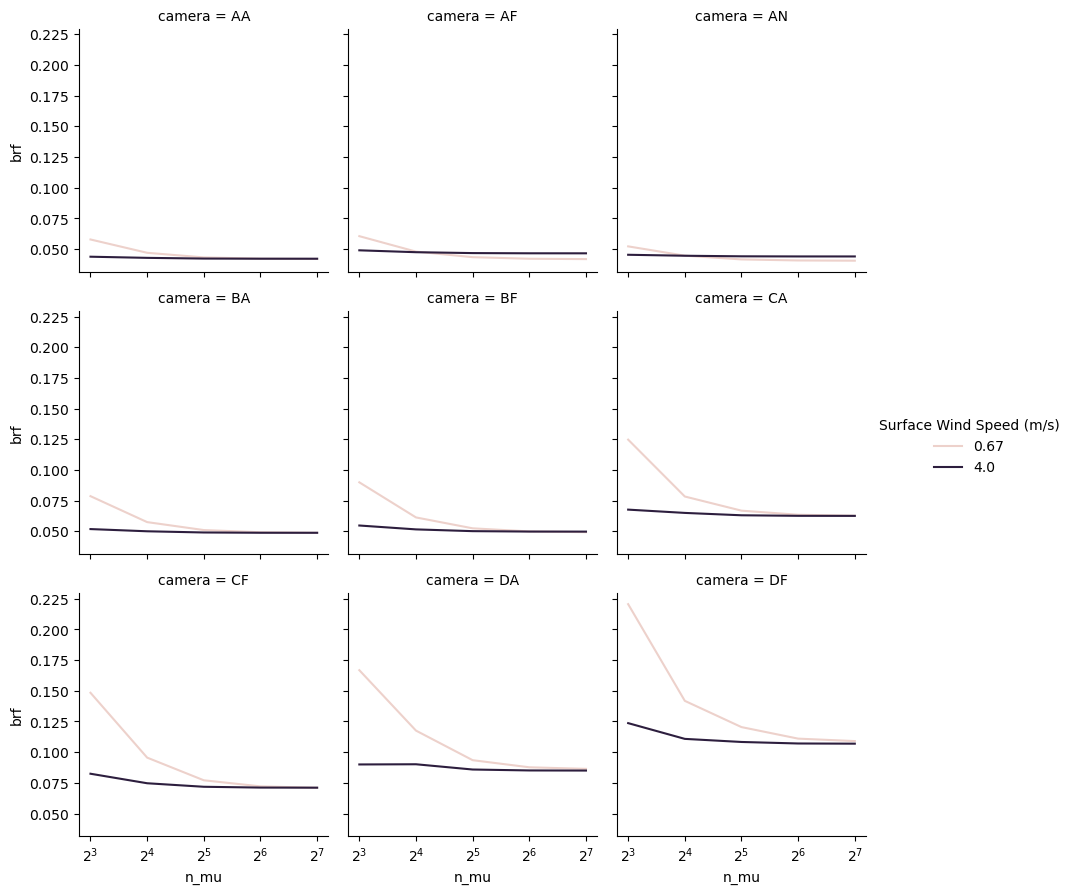

In [6]:
g = sns.FacetGrid(df_grp, col="camera", col_wrap=3, sharex=True, sharey=True)
g.map_dataframe(
    sns.lineplot,
    x="n_mu",
    y='brf',
    hue='wind_speed'
)
g.set(xscale="log")
for ax in g.axes.flatten():
    ax.set_xscale('log', base=2)
g.add_legend(title='Surface Wind Speed (m/s)')

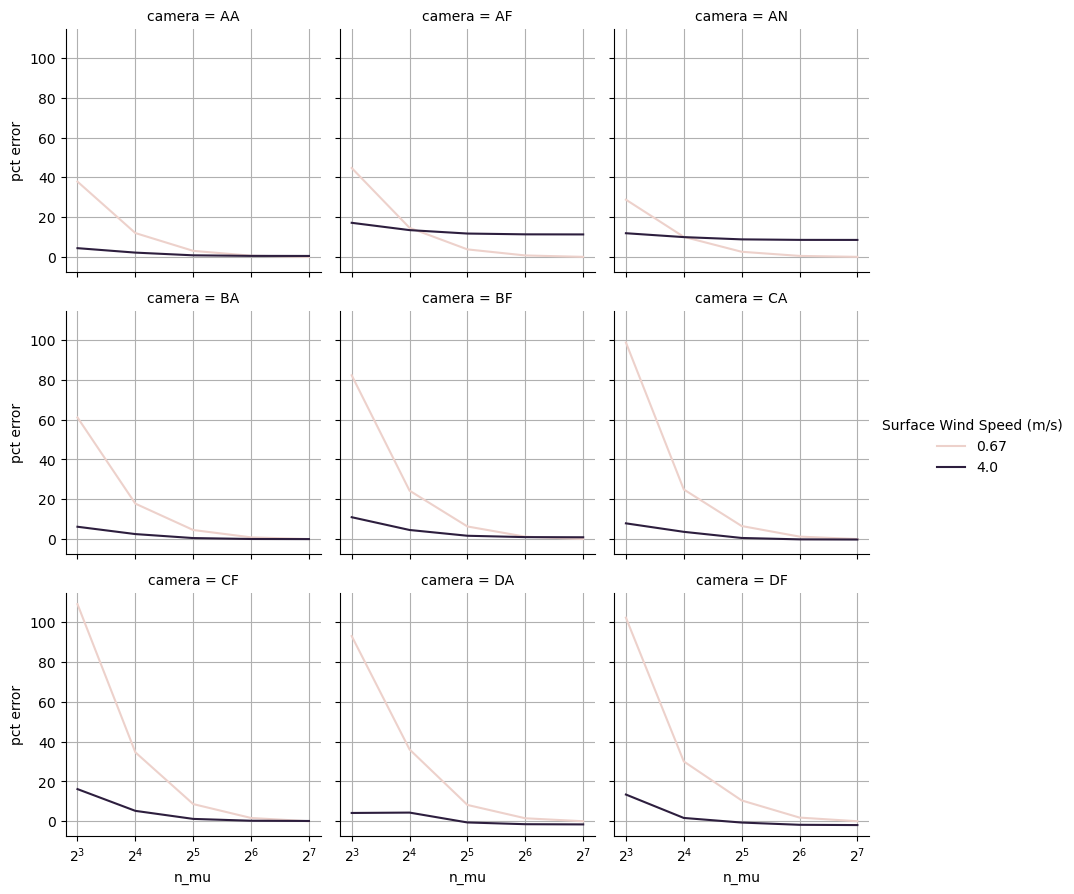

In [7]:
g = sns.FacetGrid(df_grp, col="camera", col_wrap=3, sharex=True, sharey=True)
g.map_dataframe(
    sns.lineplot,
    x="n_mu",
    y='pct error',
    hue='wind_speed'
)
g.set(xscale="log")
for ax in g.axes.flatten():
    ax.set_xscale('log', base=2)
    ax.grid()
g.add_legend(title='Surface Wind Speed (m/s)')